<img src="https://raw.githubusercontent.com/ChristophWuersch/FeatureEngineering_HS2026/main/mse_logo.png" width="400" align="right"/>
<div style="text-align: left"> <b> Machine Learning FTP_MachLe </b> <br> HS 2026 <br> <a href="mailto:christoph.wuersch@ost.ch"> Christoph Würsch </a> </div>

In [1]:
# imports
from IPython.display import Image, display
from IPython.display import HTML
import os
import requests
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

# allow plots to appear directly in the notebook
%matplotlib inline

# raw URL of this repository on GitHub (images, data)
filepath = "https://raw.githubusercontent.com/ChristophWuersch/FeatureEngineering_HS2026/main"

# **Feature Engineering – Group 1: Feature Normalization**

**Authors:** *Fritschi Simon Daniel, Rubio Gonzalez Iciar, Rohr Nathanael*

### Instructor review (2026-10-08)

This notebook (Group 1 – Feature Normalization) was checked against the group-work assignment. Changes are marked directly in the notebook:

<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span> <span style="background-color:#ffe5b4;color:#8a4b00;padding:2px 8px;border-radius:4px;font-weight:bold">[CORRECTED]</span> <span style="background-color:#d6e9f8;color:#0b4f7c;padding:2px 8px;border-radius:4px;font-weight:bold">[REVISED]</span> <span style="background-color:#e2e3e5;color:#383d41;padding:2px 8px;border-radius:4px;font-weight:bold">[REMOVED]</span>

Code changes are marked with a comment `# [ADDED]`, `# [CORRECTED]`, ... All changed cells also carry a cell tag `review-*`.

**Added**
- (ii) scale-invariance of tree-based models and role of scaling for (un)regularized linear models
- (ii) remark that scaling changes the implicit distance metric (kNN example)
- (ii) cross-validated comparison kNN / SVM / logistic regression / MLP / decision tree with and without `StandardScaler` inside a `Pipeline`
- (iv) code example: fit the scaler on the training set only; test values may leave [0, 1]
- (vi) definition of skewness
- (vii) gradient-descent example showing the effect of scaling on the condition number
- Takeaways: pipeline / cross-validation pitfall
- References for (i), (ii), (vi), (vii)

**Corrected**
- (vi) linear regression does not assume Gaussian features; Yeo–Johnson = Box–Cox on x+1 for x ≥ 0

**Revised for clarity**
- (vii) mechanism of vanishing/exploding gradients and conditioning made precise; key takeaway toned down

**Removed (beyond course scope)**
- (none)


<img src="https://raw.githubusercontent.com/ChristophWuersch/FeatureEngineering_HS2026/main/images/01_Feature_Normalization.png" width="1200"/>

## Introduction

**What is it about?**
Real-world features live on very different scales: a person's age is measured in tens of years, their income in tens of thousands of francs, and a sensor signal may vary in the millivolt range. *Feature normalization* (or *scaling*) maps all features onto a comparable range or distribution, for example zero mean and unit variance, a fixed interval $[0,1]$, or a robust range based on the median and the interquartile range. *Power transforms* such as Box–Cox and Yeo–Johnson go one step further and reduce skewness so that a feature looks closer to a Gaussian.

**Where is it used?**
Normalization is a standard preprocessing step in almost every ML pipeline (e.g. `sklearn.preprocessing.StandardScaler`, `MinMaxScaler`, `RobustScaler`, `PowerTransformer`). It is essential for distance-based learners (kNN, k-means, SVM with RBF kernels), for linear and logistic regression with regularization, for PCA, and for neural networks trained with gradient descent.

**Why is it important for Machine Learning?**
Without scaling, features with large numeric ranges dominate distances and penalty terms, regardless of how informative they are. Gradient-based optimizers converge much faster on well-conditioned, normalized inputs, and in deep networks, poorly scaled activations contribute to vanishing or exploding gradients. Choosing the *right* scaler (and fitting it on the training data only!) is a small step with a large impact on model quality.

## (i) Why normalization matters

Features can have very different numerical scales. For example, **age** is typically measured in tens of years, while **income** can be measured in tens of thousands of CHF. Without scaling, features with larger numerical values can dominate distance calculations or model optimization, even if they are not more important.

**Normalization (scaling)** transforms the features to a comparable scale. In the example below, `StandardScaler` transforms each feature to have a **mean of 0 and a standard deviation of 1**.

The plots illustrate the effect: before scaling, age and income have very different numerical ranges. After standard scaling, both features are represented on a comparable scale, so that neither feature dominates simply because of its unit or magnitude.

> **Key takeaway:** Scaling makes features comparable and prevents large numerical ranges from having an unintended influence on the model.

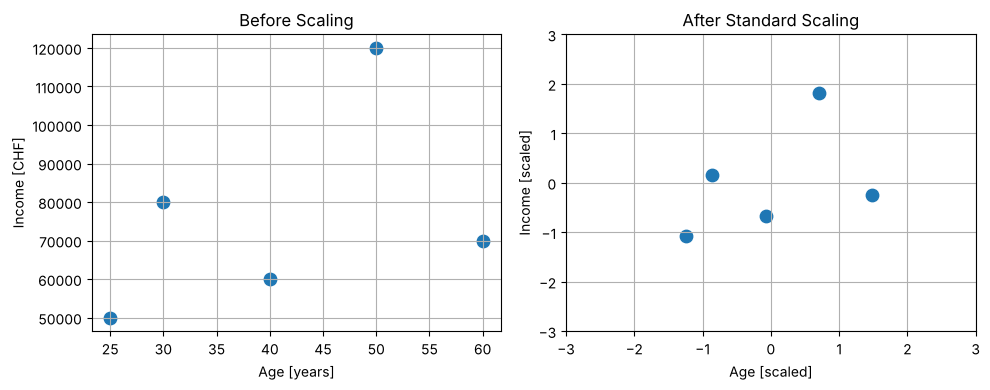

In [2]:
from sklearn.preprocessing import StandardScaler

# Example data: Age [years] and Income [CHF]
X = np.array([
    [25, 50000],
    [30, 80000],
    [40, 60000],
    [50, 120000],
    [60, 70000]
])

# Standard scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Before scaling
axes[0].scatter(X[:, 0], X[:, 1], s=80)
axes[0].set_title("Before Scaling")
axes[0].set_xlabel("Age [years]")
axes[0].set_ylabel("Income [CHF]")
axes[0].grid(True)

# After scaling
axes[1].scatter(X_scaled[:, 0], X_scaled[:, 1], s=80)
axes[1].set_title("After Standard Scaling")
axes[1].set_xlabel("Age [scaled]")
axes[1].set_ylabel("Income [scaled]")
axes[1].set_xlim(-3, 3)
axes[1].set_ylim(-3, 3)
axes[1].grid(True)

plt.tight_layout()
plt.show()

## (ii) Which learners depend on it (kNN, SVM, linear models, neural networks)

Some machine learning algorithms are particularly sensitive to feature scaling:

- **kNN:** Distances determine which samples are considered neighbors.
- **SVM:** Feature scales influence distances and the position of the decision boundary.
- **Linear models:** Scaling is especially important when regularization is used. <span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span> L1/L2 penalties act on the size of the coefficients, which depends on the unit of each feature. Unregularized least squares gives the same predictions with or without scaling (only the coefficients rescale), but iterative solvers converge faster on scaled data.
- **Neural networks:** Scaled inputs usually make gradient-based training faster and more stable.
- <span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span> **Not affected: tree-based models** (decision trees, random forests, gradient boosting). A split $x_j \le t$ only uses the *order* of the values of one feature, so any strictly monotone rescaling moves the threshold but leaves the partition, and hence the prediction, unchanged.

### Example: k-Nearest Neighbors (kNN)

The following simple example demonstrates why scaling is especially important for **distance-based algorithms such as kNN**.

We use two features, **age** and **income**, to classify a new person into one of two illustrative groups:

- **Class 0:** Lower income group
- **Class 1:** Higher income group

Without scaling, the income values are numerically much larger than the age values. Therefore, income dominates the Euclidean distance used by kNN.

After standard scaling, both features are on a comparable scale. Age and income can therefore both contribute meaningfully to the distance calculation.

As a result, scaling can change which training sample is considered the nearest neighbor and therefore also change the prediction.

<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span> Scaling does not automatically give the "right" neighbour: it replaces the arbitrary, unit-driven weighting of the features by an equal weighting in units of standard deviations. Whether that is appropriate is a modelling decision; the systematic check is cross-validation (next cell).

> **Key takeaway:** Distance-based learners such as kNN are highly sensitive to feature scales. Scaling prevents one feature from dominating simply because of its numerical magnitude.

Without scaling: Lower income
With scaling:    Higher income


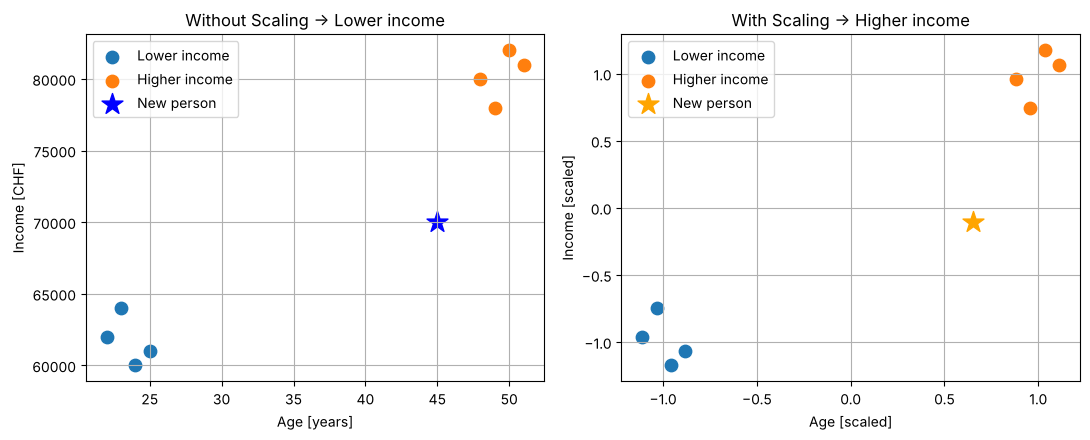

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
 
# --------------------------------------------------
# Example data
# Features: [Age (years), Income (CHF)]
# --------------------------------------------------
 
X = np.array([
    # Class 0: lower income
    [22, 62000],
    [24, 60000],
    [23, 64000],
    [25, 61000],
 
    # Class 1: higher income
    [48, 80000],
    [50, 82000],
    [49, 78000],
    [51, 81000]
])
 
y = np.array([0, 0, 0, 0, 1, 1, 1, 1])
 
# New person that should be classified
X_new = np.array([[45, 70000]])
 
class_names = {
    0: "Lower income",
    1: "Higher income"
}
 
 
# --------------------------------------------------
# 1. kNN WITHOUT scaling
# --------------------------------------------------
 
knn_raw = KNeighborsClassifier(n_neighbors=1)
knn_raw.fit(X, y)
 
pred_raw = knn_raw.predict(X_new)[0]
 
 
# --------------------------------------------------
# 2. kNN WITH standard scaling
# --------------------------------------------------
 
scaler = StandardScaler()
 
X_scaled = scaler.fit_transform(X)
X_new_scaled = scaler.transform(X_new)
 
knn_scaled = KNeighborsClassifier(n_neighbors=1)
knn_scaled.fit(X_scaled, y)
 
pred_scaled = knn_scaled.predict(X_new_scaled)[0]
 
 
# Print predictions
print("Without scaling:", class_names[pred_raw])
print("With scaling:   ", class_names[pred_scaled])
 
 
# --------------------------------------------------
# Visualization
# --------------------------------------------------
 
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
 
 
# --- Before scaling ---
 
axes[0].scatter(X[y == 0, 0],X[y == 0, 1],label="Lower income",s=80)
axes[0].scatter(X[y == 1, 0],X[y == 1, 1],label="Higher income",s=80)
axes[0].scatter(X_new[0, 0],X_new[0, 1],marker="*",s=250,label="New person",color="blue")
axes[0].set_title(f"Without Scaling → {class_names[pred_raw]}")
 
axes[0].set_xlabel("Age [years]")
axes[0].set_ylabel("Income [CHF]")
axes[0].legend()
axes[0].grid(True)
 
 
# --- After scaling ---
 
axes[1].scatter( X_scaled[y == 0, 0], X_scaled[y == 0, 1], label="Lower income", s=80)
axes[1].scatter( X_scaled[y == 1, 0], X_scaled[y == 1, 1], label="Higher income", s=80)
axes[1].scatter(X_new_scaled[0, 0],X_new_scaled[0, 1],marker="*",s=250,label="New person",color="orange")
axes[1].set_title(f"With Scaling → {class_names[pred_scaled]}")
 
axes[1].set_xlabel("Age [scaled]")
axes[1].set_ylabel("Income [scaled]")
axes[1].legend()
axes[1].grid(True)
 
plt.tight_layout()
plt.show()

<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span>

**Systematic check on real data.** The wine dataset (`sklearn.datasets.load_wine`) has features on very different
scales (e.g. `proline` ≈ 300–1700, `hue` ≈ 0.5–1.7). We compare 5-fold cross-validated accuracy with and without
`StandardScaler`. The scaler sits inside a `Pipeline`, so it is re-fitted on the training folds only (no leakage).

In [4]:
# [ADDED]
import warnings
from sklearn.datasets import load_wine
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.exceptions import ConvergenceWarning

X_wine, y_wine = load_wine(return_X_y=True)
models = {
    "kNN (k=5)":                KNeighborsClassifier(n_neighbors=5),
    "SVM (RBF kernel)":         SVC(),
    "Logistic regression (L2)": LogisticRegression(max_iter=5000),
    "Neural network (MLP)":     MLPClassifier(hidden_layer_sizes=(32,), max_iter=2000, random_state=0),
    "Decision tree":            DecisionTreeClassifier(random_state=0),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
rows = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)   # unscaled models often fail to converge
    for name, model in models.items():
        acc_raw = cross_val_score(model, X_wine, y_wine, cv=cv).mean()
        acc_std = cross_val_score(make_pipeline(StandardScaler(), model), X_wine, y_wine, cv=cv).mean()
        rows.append((name, acc_raw, acc_std))
print(pd.DataFrame(rows, columns=["model", "CV acc. raw", "CV acc. standardized"]).round(3).to_string(index=False))

                   model  CV acc. raw  CV acc. standardized
               kNN (k=5)        0.663                 0.961
        SVM (RBF kernel)        0.657                 0.983
Logistic regression (L2)        0.955                 0.983
    Neural network (MLP)        0.331                 0.972
           Decision tree        0.927                 0.927


<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span>

kNN, SVM and the MLP improve dramatically (the unscaled MLP is at chance level), the regularized logistic regression
improves moderately, and the decision tree is **exactly** unchanged, because it is scale-invariant.

## (iii) Standard scaling (z-transform)

Standard scaling makes numerical features comparable by subtracting the **mean** and dividing by the **standard deviation**. The resulting training feature has mean 0 and population standard deviation 1 (provided the original feature is not constant).

$$z_i = \frac{x_i - \mu}{\sigma}$$

- $x_i$: original value; $\mu$: feature mean; $\sigma$: standard deviation.
- $z_i$: how many standard deviations the observation is above or below the mean.

**Example:** Heights of five patients: $[150,160,170,180,190]$ cm. The mean is $170$ cm and the population standard deviation is approximately $14.14$ cm.

$$z(180)=\frac{180-170}{14.14}\approx 0.71$$

A height of 180 cm is **0.71 standard deviations above the mean**.

**Useful for:** kNN, SVM, regularized linear/logistic regression and neural networks. **Limitations:** sensitive to outliers; doesn't make data normally distributed; doesn't confine values to $[0,1]$.

In [5]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler, MinMaxScaler

heights = np.array([[150], [160], [170], [180], [190]])
scaler_z = StandardScaler()
standardized = scaler_z.fit_transform(heights)

print(pd.DataFrame({
    "Height (cm)": heights.ravel(),
    "Z-score": standardized.ravel()
}).round(2).to_string(index=False))
print("Scaled mean:", round(standardized.mean(), 2))
print("Scaled standard deviation:", round(standardized.std(), 2))

 Height (cm)  Z-score
         150    -1.41
         160    -0.71
         170     0.00
         180     0.71
         190     1.41
Scaled mean: 0.0
Scaled standard deviation: 1.0


## (iv) Min–max scaling

Min–max scaling maps the **smallest observed training value to 0**, the **largest to 1**, and other values proportionally between them.

$$x'_i = \frac{x_i - x_{\min}}{x_{\max} - x_{\min}}$$

- $x_i$: original value; $x_{\min}$: minimum; $x_{\max}$: maximum.
- $x'_i$: rescaled value between 0 and 1 for values within the training range.

**Example:** Patient ages $[20,30,40,50,60]$.

$$x'(30)=\frac{30-20}{60-20}=0.25$$

$$x'(50)=\frac{50-20}{60-20}=0.75$$

So the transformed ages are $[0,0.25,0.50,0.75,1]$.

**Useful when:** inputs should have a defined numerical range. **Limitations:** highly sensitive to extreme minimum/maximum values; unseen data can transform outside $[0,1]$.

**Difference:** standard scaling uses mean and standard deviation; min–max scaling uses the minimum and maximum.

In [6]:
ages = np.array([[20], [30], [40], [50], [60]])
scaler_mm = MinMaxScaler(feature_range=(0, 1))
scaled_ages = scaler_mm.fit_transform(ages)

print(pd.DataFrame({
    "Age": ages.ravel(),
    "Min-Max": scaled_ages.ravel()
}).to_string(index=False))

 Age  Min-Max
  20     0.00
  30     0.25
  40     0.50
  50     0.75
  60     1.00


### Visual comparison

Both methods preserve the ordering of values. **Standard scaling** centers the data at 0, whereas **min–max scaling** maps the observed range to 0–1.

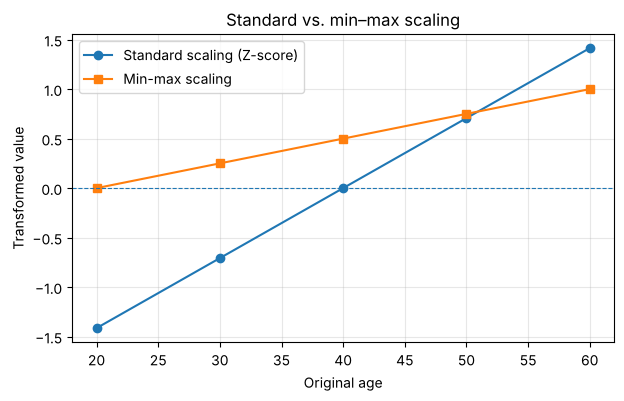

In [7]:
import matplotlib.pyplot as plt

values = np.array([[20], [30], [40], [50], [60]])
z = StandardScaler().fit_transform(values).ravel()
mm = MinMaxScaler().fit_transform(values).ravel()

plt.figure(figsize=(7, 4))
plt.plot(values.ravel(), z, "o-", label="Standard scaling (Z-score)")
plt.plot(values.ravel(), mm, "s-", label="Min-max scaling")
plt.axhline(0, linestyle="--", linewidth=0.8)
plt.xlabel("Original age")
plt.ylabel("Transformed value")
plt.title("Standard vs. min–max scaling")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Important ML practice:** fit a scaler on the **training data only**, then use the fitted scaler's `.transform()` method on validation and test data to avoid data leakage.

In [8]:
# [ADDED]
# Correct usage: statistics from the TRAINING set only, then reuse them on new data
ages_train = np.array([[20], [30], [40], [50], [60]])
ages_test  = np.array([[18], [45], [70]])            # unseen data, partly outside the training range

mm = MinMaxScaler().fit(ages_train)                   # learns data_min_ = 20, data_max_ = 60
print("learned min / max      :", mm.data_min_, mm.data_max_)
print("scaled test values     :", mm.transform(ages_test).ravel().round(3))   # -> outside [0, 1] is fine
# Wrong: MinMaxScaler().fit(np.vstack([ages_train, ages_test])) would let the test set influence the training data.
# In cross-validation use make_pipeline(scaler, model) so the scaler is re-fitted in every training fold.

learned min / max      : [20.] [60.]
scaled test values     : [-0.05   0.625  1.25 ]


## (v) Robust scaling (median and IQR)

**Idea in one sentence:** Centre each feature on its **median** and divide by its **interquartile range (IQR)**, i.e. the spread of the middle 50 % of the data:

$$
x_{\text{scaled}} = \frac{x - \text{median}(x)}{Q_3 - Q_1}
$$

where $Q_1$ and $Q_3$ are the 25th and 75th percentiles.

**Why "robust"?** The mean and standard deviation (used by standard scaling) are pulled away by a few extreme values. The median and the IQR are not, because they depend only on the *order* of the data and not on how far away the outliers are. As a result, the bulk of the data stays centred around 0 with a sensible spread, even when outliers are present.

**Good to know:**
- Robust scaling does **not remove** outliers. They are still there, just on a different scale.
- The result is **not bounded** to a fixed range such as $[0, 1]$.
- Use it when a feature contains outliers you want to keep, e.g. incomes, prices or sensor spikes.
- In scikit-learn: `sklearn.preprocessing.RobustScaler`. As with every scaler, fit it on the **training data only**.

Median = 5959 CHF, Q1 = 5353, Q3 = 6601, IQR = 1248 CHF
Manual result == RobustScaler: True
Mean = 6768 CHF, Std = 6871 CHF  (both inflated by the outliers)


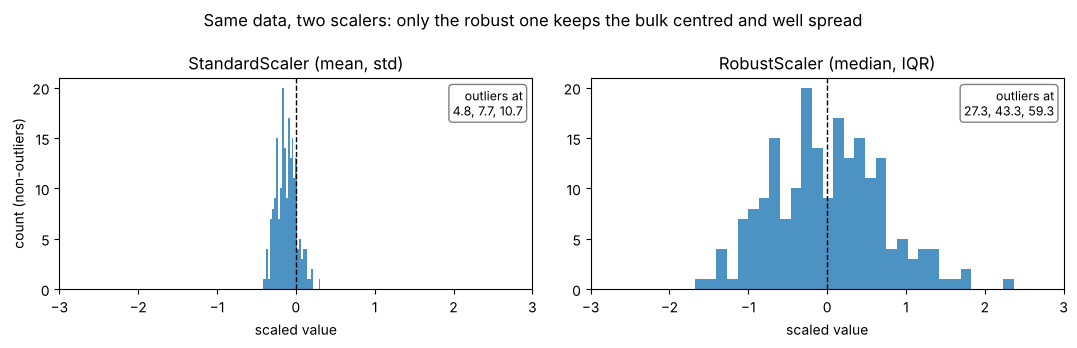

In [9]:
from sklearn.preprocessing import StandardScaler, RobustScaler

# --- 1. Toy feature: monthly income (CHF) with a few extreme outliers ---
rng = np.random.default_rng(42)                     # fixed seed -> reproducible results
income = rng.normal(loc=6000, scale=1000, size=200) # 200 "normal" incomes around 6000 CHF
income = np.append(income, [40000, 60000, 80000])   # 3 extreme outliers (e.g. top managers)
X = income.reshape(-1, 1)                           # scikit-learn expects shape (n_samples, n_features)

# --- 2. Robust scaling "by hand": (x - median) / IQR ---
median = np.median(X)                    # middle value -> barely affected by outliers
q1, q3 = np.percentile(X, [25, 75])      # 1st and 3rd quartile
iqr = q3 - q1                            # interquartile range = spread of the middle 50 %
X_manual = (X - median) / iqr
print(f"Median = {median:.0f} CHF, Q1 = {q1:.0f}, Q3 = {q3:.0f}, IQR = {iqr:.0f} CHF")

# --- 3. Same with scikit-learn (in a real pipeline: fit on the TRAINING data only!) ---
X_robust = RobustScaler().fit_transform(X)      # default: quantile_range=(25.0, 75.0)
print("Manual result == RobustScaler:", np.allclose(X_manual, X_robust))

# --- 4. Comparison: StandardScaler uses mean and std, which the outliers distort ---
X_std = StandardScaler().fit_transform(X)
print(f"Mean = {X.mean():.0f} CHF, Std = {X.std():.0f} CHF  (both inflated by the outliers)")

# --- 5. Visualise where the 200 'normal' values end up after scaling ---
inliers = slice(0, 200)                  # the first 200 entries are the non-outliers
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharex=True)
for ax, data, title in zip(axes, [X_std, X_robust],
                           ["StandardScaler (mean, std)", "RobustScaler (median, IQR)"]):
    ax.hist(data[inliers], bins=30, color="tab:blue", alpha=0.8)
    ax.axvline(0, color="k", ls="--", lw=1)          # the new centre of the data
    ax.set_title(title)
    ax.set_xlabel("scaled value")
    ax.set_xlim(-3, 3)
    out = data[200:].ravel()                         # the 3 outliers lie far off-plot -> shown as text
    ax.text(0.98, 0.95, "outliers at\n" + ", ".join(f"{v:.1f}" for v in out),
            transform=ax.transAxes, ha="right", va="top", fontsize=9,
            bbox=dict(boxstyle="round", fc="white", ec="grey"))
axes[0].set_ylabel("count (non-outliers)")
plt.suptitle("Same data, two scalers: only the robust one keeps the bulk centred and well spread")
plt.tight_layout()
plt.show()

<span style="background-color:#ffe5b4;color:#8a4b00;padding:2px 8px;border-radius:4px;font-weight:bold">[CORRECTED]</span> *linear regression does not assume Gaussian features (only LDA/GNB do); Yeo–Johnson vs. Box–Cox stated precisely.*

## (vi) Skewness and power transforms: Box–Cox and Yeo–Johnson

**What is skewness?** A feature is *skewed* when its distribution is lopsided, with most values bunched on one side and a long tail on the other. Typical examples are incomes, house prices or waiting times: many small values and a few very large ones (right skew, skewness $> 0$). A symmetric distribution such as the Gaussian has skewness $= 0$. <span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span> Formally, $\gamma_1 = \mathbb{E}[(X-\mu)^3]/\sigma^3$ (`scipy.stats.skew`).

**Why does it matter?** Some models explicitly assume Gaussian features, e.g. LDA and Gaussian Naive Bayes (Gaussian class-conditional densities). Linear regression does **not** require Gaussian features (its assumptions concern the residuals), but a power/log transform of a skewed feature often makes its relation to the target more linear and reduces the leverage of the few extreme values. A long tail also makes a few large values dominate. Scaling alone does not help here, because it only shifts and stretches the data and **never changes its shape**.

**Idea of power transforms:** Apply a non-linear function that **compresses the long tail** and pulls the distribution into a more symmetric, Gaussian-like shape. The strength of the transform is controlled by a single parameter $\lambda$, which is **estimated automatically from the (training) data** (maximum likelihood).

### Box–Cox

$$
x^{(\lambda)} =
\begin{cases}
\dfrac{x^{\lambda} - 1}{\lambda}, & \lambda \neq 0 \\[6pt]
\ln(x), & \lambda = 0
\end{cases}
$$

- $\lambda = 1$: no change in shape, $\lambda = 0.5$: similar to a square root, $\lambda = 0$: log transform.
- **Limitation:** only works for **strictly positive** data ($x > 0$).

### Yeo–Johnson

$$
x^{(\lambda)} =
\begin{cases}
\dfrac{(x+1)^{\lambda} - 1}{\lambda}, & \lambda \neq 0,\ x \geq 0 \\[6pt]
\ln(x+1), & \lambda = 0,\ x \geq 0 \\[6pt]
-\dfrac{(1-x)^{2-\lambda} - 1}{2-\lambda}, & \lambda \neq 2,\ x < 0 \\[6pt]
-\ln(1-x), & \lambda = 2,\ x < 0
\end{cases}
$$

- Same idea as Box–Cox, but it also handles **zeros and negative values**, e.g. profit/loss or temperature changes.
- For $x \ge 0$ Yeo–Johnson is exactly Box–Cox applied to $x+1$.

**In scikit-learn:** `sklearn.preprocessing.PowerTransformer(method="box-cox")` or `method="yeo-johnson"` (default). By default it also standardises the output to mean 0 and std 1. As always, fit it on the **training data only**.

Box-Cox     lambda = -0.056
Yeo-Johnson lambda = -0.057
Skewness original    :   2.13
Skewness Box-Cox     :   0.00
Skewness Yeo-Johnson :   0.00

Box-Cox on negative data fails: The Box-Cox transformation can only be applied to strictly positive data
Yeo-Johnson on the same data works, skewness: 2.13 -> 0.31


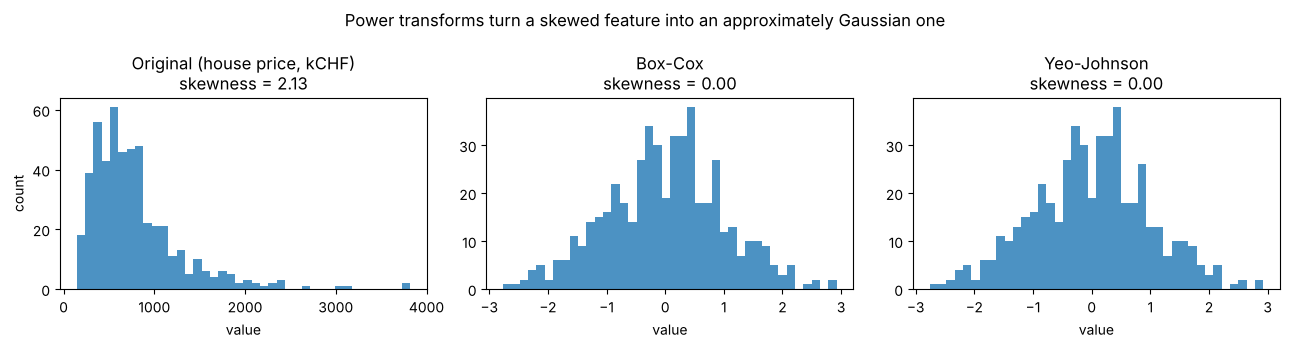

In [10]:
from scipy.stats import skew
from sklearn.preprocessing import PowerTransformer

# --- 1. Toy feature: house prices (kCHF), strongly right-skewed (log-normal) ---
rng = np.random.default_rng(42)                        # fixed seed -> reproducible results
price = rng.lognormal(mean=6.5, sigma=0.6, size=500)   # all values > 0, long tail to the right
X = price.reshape(-1, 1)                               # scikit-learn expects shape (n_samples, n_features)

# --- 2. Fit both power transforms (standardize=True by default -> output has mean 0, std 1) ---
bc = PowerTransformer(method="box-cox")      # only works for strictly positive data
yj = PowerTransformer(method="yeo-johnson")  # default in scikit-learn, works for any real values
X_bc = bc.fit_transform(X)                   # in a real pipeline: fit on the TRAINING data only!
X_yj = yj.fit_transform(X)

# The best lambda is estimated from the data (maximum likelihood); lambda close to 0 ~ log transform
print(f"Box-Cox     lambda = {bc.lambdas_[0]:.3f}")
print(f"Yeo-Johnson lambda = {yj.lambdas_[0]:.3f}")

# Skewness: 0 = symmetric, > 0 = long right tail
for name, data in [("original", X), ("Box-Cox", X_bc), ("Yeo-Johnson", X_yj)]:
    print(f"Skewness {name:<12}: {skew(data.ravel()):6.2f}")

# --- 3. The key difference: data containing zeros or negative values ---
profit = price - 800                                   # e.g. profit/loss -> contains negative values
try:
    PowerTransformer(method="box-cox").fit(profit.reshape(-1, 1))
except ValueError as err:                              # Box-Cox refuses non-positive data
    print("\nBox-Cox on negative data fails:", err)
X_profit_yj = PowerTransformer(method="yeo-johnson").fit_transform(profit.reshape(-1, 1))
print(f"Yeo-Johnson on the same data works, skewness: {skew(profit):.2f} -> {skew(X_profit_yj.ravel()):.2f}")

# --- 4. Visualise: original vs. transformed distributions ---
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, data, title in zip(axes, [X, X_bc, X_yj],
                           ["Original (house price, kCHF)", "Box-Cox", "Yeo-Johnson"]):
    ax.hist(data.ravel(), bins=40, color="tab:blue", alpha=0.8)
    ax.set_title(f"{title}\nskewness = {skew(data.ravel()):.2f}")
    ax.set_xlabel("value")
axes[0].set_ylabel("count")
plt.suptitle("Power transforms turn a skewed feature into an approximately Gaussian one")
plt.tight_layout()
plt.show()

<span style="background-color:#d6e9f8;color:#0b4f7c;padding:2px 8px;border-radius:4px;font-weight:bold">[REVISED]</span> *mechanism made precise (conditioning, product of Jacobians, saturation); takeaway no longer suggests that input scaling alone solves the problem.*

## (vii) Outlook for neural networks: vanishing and exploding gradients

**Conditioning (why input scaling helps gradient descent).** For a linear model or the first layer of a network
with MSE loss, the Hessian is $H = \tfrac{1}{n}X^\top X$. Gradient descent needs a step size $\eta < 2/\lambda_{\max}(H)$,
and the error along the flattest direction only shrinks by a factor $\approx 1 - \lambda_{\min}/\lambda_{\max} = 1 - 1/\kappa$
per step. Features on very different scales (or with large non-zero means) give a huge condition number $\kappa$:
the loss surface is a long, narrow valley, and gradient descent zig-zags with tiny steps. Centring and scaling the
inputs makes $\kappa$ close to 1 (see the example below).

**Vanishing / exploding gradients.** Backpropagation multiplies one Jacobian per layer,
$\partial L/\partial \mathbf h_1 = \big(\prod_{l} \mathbf W_l^\top \operatorname{diag}\,\sigma'(\mathbf z_l)\big)\,\partial L/\partial \mathbf h_L$.
If these factors have norms consistently **below 1**, the gradient shrinks exponentially with depth (**vanishing**) and
the early layers stop learning; **above 1**, it grows exponentially (**exploding**) and training becomes unstable.
Large, unscaled inputs additionally push sigmoid/tanh units into saturation ($\sigma' \approx 0$) already in the first layer.

**Normalized inputs** (mean ≈ 0, similar scale) keep the first layer well-conditioned and out of saturation. Inside the
network, the same idea continues with careful weight initialisation (e.g. Xavier/He), **Batch Normalization** or
**Layer Normalization** (re-normalise the activations between layers), residual connections and gradient clipping.

> **Key takeaway:** Input scaling is the first line of defence: necessary, but not sufficient. It fixes the conditioning
> at the input; deep networks additionally need proper initialisation and normalization layers.

raw features          : kappa =  2.57e+04, excess loss after 300 steps = 1.22e-01
standardized features : kappa =      1.14, excess loss after 300 steps = 6.94e-18


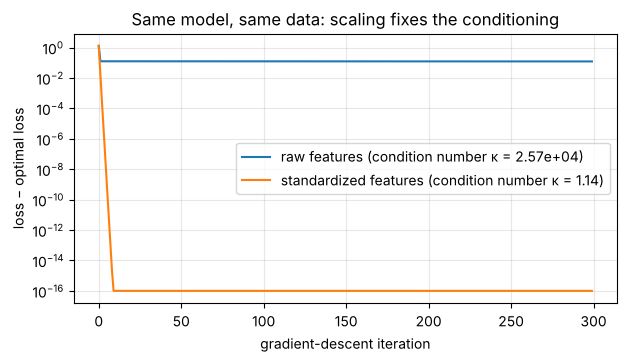

In [11]:
# [ADDED]
# Gradient descent on least squares: raw vs. standardized features (same data, both centred)
rng = np.random.default_rng(0)
n = 200
age    = rng.normal(40, 10, n)          # years
income = rng.normal(6000, 1500, n)      # CHF per month
y_gd   = 0.05 * age + 0.001 * income + rng.normal(0, 0.3, n)

def run_gd(X, y, iters=300):
    X, y = X - X.mean(0), y - y.mean()
    H = X.T @ X / len(y)                              # Hessian of the MSE loss (1/2 * mean squared error)
    eig = np.linalg.eigvalsh(H)
    eta = 1.0 / eig.max()                             # largest "safe" step size
    w_opt = np.linalg.lstsq(X, y, rcond=None)[0]
    loss = lambda w: 0.5 * np.mean((X @ w - y) ** 2)
    w, excess = np.zeros(X.shape[1]), []
    for _ in range(iters):
        excess.append(loss(w) - loss(w_opt))
        w -= eta * X.T @ (X @ w - y) / len(y)
    return eig.max() / eig.min(), np.array(excess)

X_raw = np.c_[age, income]
X_std = StandardScaler().fit_transform(X_raw)
plt.figure(figsize=(7, 3.5))
for X_, label in [(X_raw, "raw features"), (X_std, "standardized features")]:
    kappa, excess = run_gd(X_, y_gd)
    plt.semilogy(np.maximum(excess, 1e-16), label=f"{label} (condition number κ = {kappa:.3g})")
    print(f"{label:<22}: kappa = {kappa:9.3g}, excess loss after 300 steps = {excess[-1]:.2e}")
plt.xlabel("gradient-descent iteration"); plt.ylabel("loss − optimal loss")
plt.title("Same model, same data: scaling fixes the conditioning")
plt.legend(); plt.grid(alpha=0.3); plt.show()

<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span>

With raw features ($\kappa \approx 2.6\cdot 10^4$), the step size is limited by the `income` direction and the
`age` coefficient is practically never learned: the loss stalls. After standardization ($\kappa \approx 1$),
gradient descent converges in a few steps. The same effect slows down the training of the first layer of a network.

## Takeaways

- **What should every ML practitioner remember?**
  - Scale features so that no feature dominates just because of its unit or magnitude.
  - Standard scaling is the default, min–max scaling gives a fixed range, robust scaling handles outliers, and power transforms fix skewness.
  - Scaling changes the range, power transforms change the shape.

- **What are common pitfalls?**
  - Fitting the scaler on the whole dataset instead of the **training data only**, which causes data leakage.
  - Using standard or min–max scaling on data with strong outliers.
  - Applying Box–Cox to zero or negative values. Use Yeo–Johnson instead.
  - <span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span> Scaling outside the cross-validation loop: put the scaler into a `Pipeline` so it is re-fitted on every training fold, and reuse the *fitted* scaler at inference time.

- **When does this technique really matter?**
  - For distance-based models (kNN, k-means, SVM), regularised linear models, PCA and neural networks.
  - Hardly at all for tree-based models (decision trees, random forests, gradient boosting), which are scale-invariant.

## References

*Cite the sources of all figures, diagrams and code snippets (URLs are sufficient).*

(iii)
MachLe Lecture 1, slide 64.

(iv)
MachLe Lecture 1

(v)
https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.RobustScaler.html

(vi)
1. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PowerTransformer.html
2. https://scikit-learn.org/stable/auto_examples/preprocessing/plot_map_data_to_normal.html

(vii)
https://pytorch.org/docs/stable/generated/torch.nn.BatchNorm1d.html

<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span>

(i), (ii)
- https://scikit-learn.org/stable/modules/preprocessing.html
- https://scikit-learn.org/stable/auto_examples/preprocessing/plot_scaling_importance.html
- Wine dataset: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_wine.html

(vi)
- G. E. P. Box, D. R. Cox (1964), An analysis of transformations, JRSS B 26(2): https://doi.org/10.1111/j.2517-6161.1964.tb00553.x
- I.-K. Yeo, R. A. Johnson (2000), A new family of power transformations to improve normality or symmetry, Biometrika 87(4): https://doi.org/10.1093/biomet/87.4.954

(vii)
- Y. LeCun, L. Bottou, G. Orr, K.-R. Müller (1998), Efficient BackProp: http://yann.lecun.com/exdb/publis/pdf/lecun-98b.pdf
- X. Glorot, Y. Bengio (2010), Understanding the difficulty of training deep feedforward neural networks: https://proceedings.mlr.press/v9/glorot10a.html
- S. Ioffe, C. Szegedy (2015), Batch Normalization: https://arxiv.org/abs/1502.03167
